In [3]:
#Import all needed libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [5]:
# Load dataset
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [37]:
# Examine the table
display(df.head())
df['category'].value_counts()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: category, Length: 296, dtype: int64

In [27]:
#1. **Frequency Tables**:
#    - Generate a frequency table for the product `category`.
#    - Which are the top 5 most listed product categories?

freq_table = df['category'].value_counts().sort_values(ascending=False)
freq_table.columns = ['Category', 'Frequency']
print('Frequency table for all Amazon categories:')
display(freq_table)
print(f"Count for all categories: {len(df['category'].value_counts())}")
print(f'\nFrequency table for Top 5 Amazon categories:')
top5_table = freq_table.head(5)
display(top5_table)

Frequency table for all Amazon categories:


Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: category, Length: 296, dtype: int64

Count for all categories: 296

Frequency table for Top 5 Amazon categories:


Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: category, dtype: int64

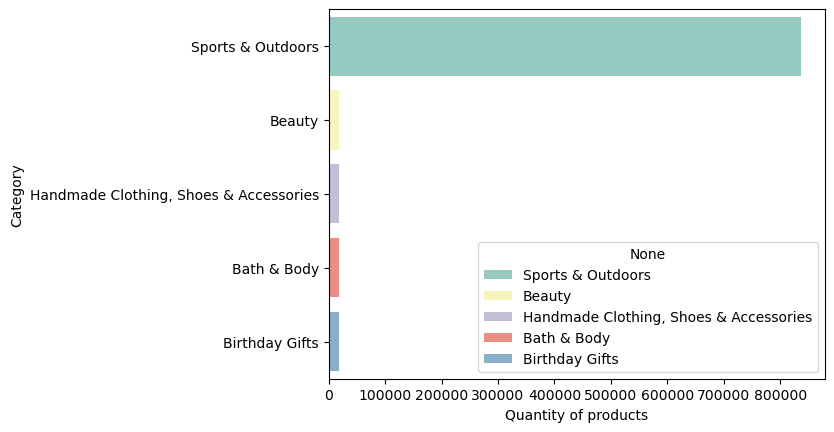

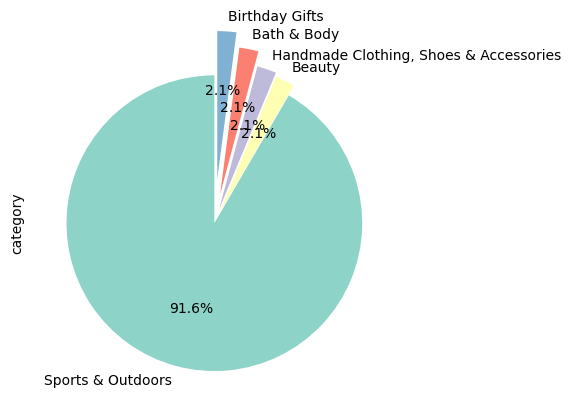

In [36]:
#2. **Visualizations**:
#    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*

fig, axes = plt.subplots()
ax=sns.barplot(y=top5_table.index, x=top5_table.values, palette="Set3", hue=top5_table.index, legend=True )
axes.set_ylabel("Category")
axes.set_xlabel("Quantity of products")
sns.move_legend(ax, "lower right")
plt.show()

#    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?
top5_table.plot.pie(autopct='%.1f%%',startangle=90, colors=sns.color_palette("Set3"), explode=(0,0.075,0.1,0.2, 0.3));

plt.show()

Object `common` not found.
----------Measures of Centrality----------
Price mean: 89.24
Price median: 19.09
Price mode: 9.99

----------Measures of Dispersion----------
Price variance: 119445.49
Price std. dev.: 345.61
Price range: 100000.0
Price has a 25th quartile of 9.99 and 75th quartile of 45.99

----------Histogram of prices----------


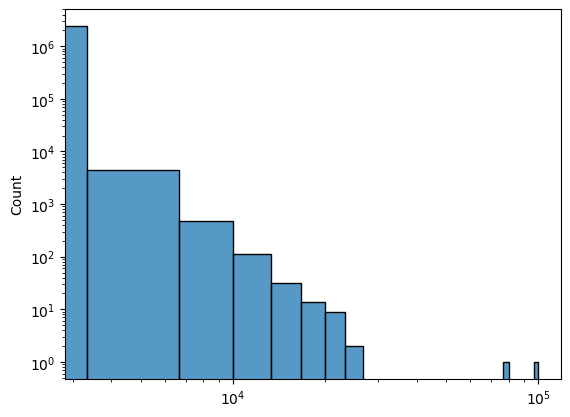

In [88]:
### Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

#1. **Measures of Centrality**:
#    - Calculate the mean, median, and mode for the `price` of products.
#    - What's the average price point of products listed? How does this compare with the most common price point (mode)?

mean_price = round(df['price'].mean(),2)
median_price = df['price'].median()
mode_price = df['price'].mode()[0]

print("-"*10+"Measures of Centrality"+"-"*10)
print(f'Price mean: {mean_price}') 
print(f'Price median: {median_price}')
print(f'Price mode: {mode_price}'), 

#2. **Measures of Dispersion**:
#    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
#    - How varied are the product prices? Are there any indicators of a significant spread in prices?

variance_price = round(df['price'].var(),2)
std_price = round(df['price'].std(),2)
price_range = df['price'].max() - df['price'].min()
price_25q = df['price'].quantile(0.25)
price_75q = df['price'].quantile(0.75)

print("\n"+"-"*10+"Measures of Dispersion"+"-"*10)
print(f'Price variance: {variance_price}'), 
print(f'Price std. dev.: {std_price}')
print(f'Price range: {price_range}')
print(f'Price has a 25th quartile of {price_25q} and 75th quartile of {price_75q}')


#3. **Visualizations**:
#    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
#    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 

print("\n"+"-"*10+"Histogram of prices"+"-"*10)
# Option 1
#sns.histplot(data = df, x="price", bins=50);
# Option 2
fig, axes = plt.subplots()
sns.histplot(x=df["price"].values,  bins=30, ax=axes)
axes.set_yscale("log")
axes.set_xscale("log")
plt.show()

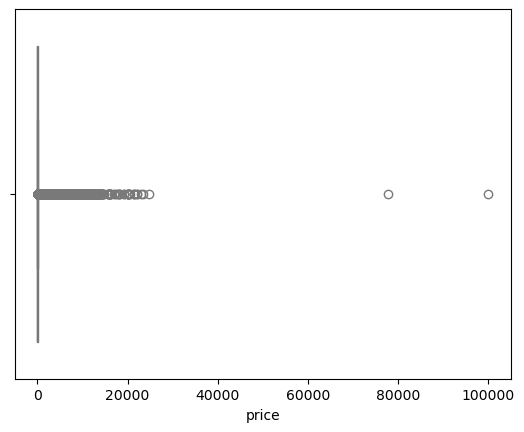

In [75]:
#    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 
fig, axes = plt.subplots()
sns.boxplot(x = df['price'], color="lightblue", ax=axes);
plt.show()

In [95]:
### Part 3: Unpacking Product Ratings

#**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

#1. **Measures of Centrality**:
#    - Calculate the mean, median, and mode for the `rating` of products.
#    - How do customers generally rate products? Is there a common trend?

mean_rating = round(df['stars'].mean(),2)
median_rating = df['stars'].median()
mode_rating = df['stars'].mode()[0]

print("-"*10+"Measures of Centrality"+"-"*10)
print(f'Rating mean: {mean_rating}') 
print(f'Rating median: {median_rating}')
print(f'Rating mode: {mode_rating}')

#2. **Measures of Dispersion**:
#    - Determine the variance, standard deviation, and interquartile range for product `rating`.
#    - Are the ratings consistent, or is there a wide variation in customer feedback?

var_rating = round(df['stars'].var(),2)
std_rating = round(df['stars'].std(),2)
rating_25q = df['stars'].quantile(0.25)
rating_75q = df['stars'].quantile(0.75)

print("\n"+"-"*10+"Measures of Dispersion"+"-"*10)
print(f'Rating variance: {var_rating}'), 
print(f'Rating std. dev.: {std_rating}')
print(f'Rating has a 25th quartile of {rating_25q} and 75th quartile of {rating_75q}')

----------Measures of Centrality----------
Rating mean: 2.15
Rating median: 0.0
Rating mode: 0.0

----------Measures of Dispersion----------
Rating variance: 4.82
Rating std. dev.: 2.19
Rating has a 25th quartile of 0.0 and 75th quartile of 4.4


Wide variety in customer feedback with many low ratings

In [98]:
#3. **Shape of the Distribution**:
#    - Calculate the skewness and kurtosis for the `rating` column. 
#    - Are the ratings normally distributed, or do they lean towards higher or lower values?

skewness_rating = df['stars'].skew()
kurtosis_rating = df['stars'].kurtosis()

skewness_rating, kurtosis_rating

(0.08120735761080985, -1.9260061280432985)

Ratings lean towards lower values, with quite some variability. The distribution is not as "peaked".

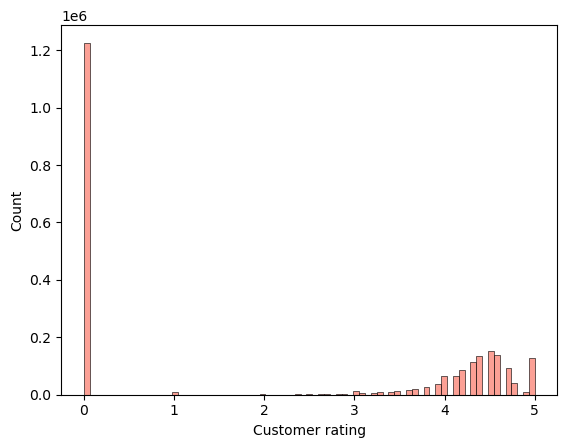

In [101]:
#4. **Visualizations**:
#    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

fig, axes = plt.subplots()
sns.histplot(df['stars'], color="salmon", ax=axes);
axes.set_xlabel('Customer rating')
axes.set_ylabel('Count')
plt.show()

There are a lot of zero ratings.